# Prepared DEM over the Vienna AOI

Plots the merged DEM from `dem_preparation` (`vienna_bevdsm_cop30_ellipsoid_10m.tif`) inside the Vienna AOI bbox.

* **Inside the fine grid**: BEV DSM (10 m, surface model, so buildings and vegetation are included), shifted to ellipsoidal heights / ITRF2020
* **Outside**: Copernicus GLO-30 (ellipsoidal), blended over `blend_width_m` at the border

Heights are **ellipsoidal (WGS84)**, so they are about 45-50 m higher than the usual orthometric heights for Vienna.

The full GeoTIFF covers all bursts (~25k x 19k px), so only a window around the AOI is read.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import LightSource
from matplotlib.patches import Rectangle
from rasterio.windows import from_bounds

## Configuration

In [2]:
DEM_DIR = Path("/home/lukas/projects/ADUCAT/data/dem/dem_preparation/output")
DEM_FILE = DEM_DIR / "vienna_bevdsm_cop30_ellipsoid_10m.tif"
REPORT_FILE = DEM_DIR / "vienna_bevdsm_cop30_ellipsoid_10m_report.json"

# AOI bbox (west, south, east, north) in WGS84
AOI_BOUNDS = (16.18099875016676, 48.11744311620298, 16.587587299348154, 48.324307364563005)
PAD_DEG = 0.02          # margin around the AOI for the read window

# colour stretch (percentiles of valid pixels inside the AOI)
CLIP_PERCENTILES = (1, 99)
HILLSHADE_VERT_EXAG = 2.0

## Metadata and report

In [3]:
report = json.loads(REPORT_FILE.read_text())
fine = report["fine_grid"]["grid"]
fine_bounds = (
    fine["west"],
    fine["north"] - fine["height"] * fine["delta_lat"],
    fine["west"] + fine["width"] * fine["delta_lon"],
    fine["north"],
)

with rasterio.open(DEM_FILE) as src:
    print(f"CRS:        {src.crs.to_string()}")
    print(f"Size:       {src.width} x {src.height} px")
    print(f"Pixel size: {src.res[0]:.3e} deg x {src.res[1]:.3e} deg")
    print(f"Bounds:     {tuple(round(b, 4) for b in src.bounds)}")
    print(f"Nodata:     {src.nodata}")

print(f"\nFine (BEV) grid bounds: {tuple(round(b, 4) for b in fine_bounds)}")
print(f"Blend width: {report['merge']['blend_width_m']} m")
print(f"BEV - COP30 in AOI [m]: {report['bev_minus_coarse_in_aoi_m']}")

CRS:        EPSG:4326
Size:       25410 x 18788 px
Pixel size: 1.346e-04 deg x 8.993e-05 deg
Bounds:     (14.8393, 47.3634, 18.2589, 49.053)
Nodata:     -32768.0

Fine (BEV) grid bounds: (16.1413, 48.0843, 16.6292, 48.3575)
Blend width: 300.0 m
BEV - COP30 in AOI [m]: {'median': 0.2401275634765625, 'percentile_5': -6.55059814453125, 'percentile_95': 7.503572082519526, 'pixel_count': 6948300}


## Read the DEM window around the AOI

In [4]:
w, s, e, n = AOI_BOUNDS
read_bounds = (w - PAD_DEG, s - PAD_DEG, e + PAD_DEG, n + PAD_DEG)

with rasterio.open(DEM_FILE) as src:
    window = from_bounds(*read_bounds, transform=src.transform).round_offsets().round_lengths()
    dem = src.read(1, window=window, masked=True).astype("float32")
    win_transform = src.window_transform(window)
    nodata = src.nodata

extent = rasterio.transform.array_bounds(dem.shape[0], dem.shape[1], win_transform)
extent = (extent[0], extent[2], extent[1], extent[3])   # (left, right, bottom, top) for imshow

# pixel mask for the AOI itself
rows, cols = np.indices(dem.shape)
lon = win_transform.c + (cols + 0.5) * win_transform.a
lat = win_transform.f + (rows + 0.5) * win_transform.e
in_aoi = (lon >= w) & (lon <= e) & (lat >= s) & (lat <= n)

vals = dem.compressed() if np.ma.is_masked(dem) else dem.data.ravel()
aoi_vals = dem.data[in_aoi & ~np.ma.getmaskarray(dem)]
vmin, vmax = np.percentile(aoi_vals, CLIP_PERCENTILES)

print(f"Window shape: {dem.shape}")
print(f"Nodata pixels in AOI: {(in_aoi & np.ma.getmaskarray(dem)).sum()}")
print(f"AOI height stats [m, ellipsoidal]: min={aoi_vals.min():.1f}  p1={vmin:.1f}  "
      f"median={np.median(aoi_vals):.1f}  p99={vmax:.1f}  max={aoi_vals.max():.1f}")

Window shape: (2745, 3318)
Nodata pixels in AOI: 0
AOI height stats [m, ellipsoidal]: min=187.8  p1=196.0  median=227.7  p99=522.3  max=625.7


## DEM with hillshade

Coloured heights over a hillshade. Red = AOI bbox, dashed = extent of the fine BEV grid (everything outside is COP30).
The aspect is set to `1/cos(lat)` so the plot is not stretched in longitude.

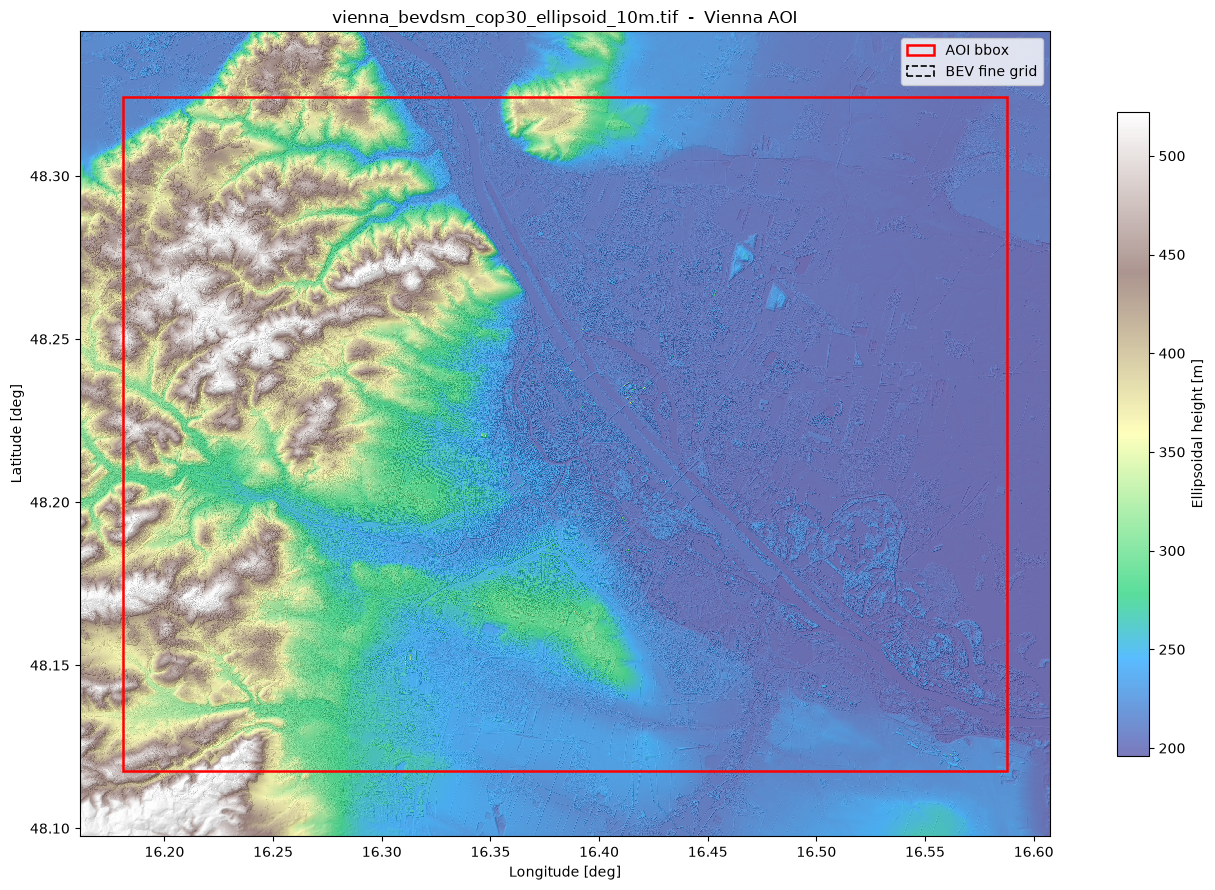

In [5]:
# hillshade needs dx, dy in metres
lat_c = 0.5 * (s + n)
dx = abs(win_transform.a) * 111_320 * np.cos(np.deg2rad(lat_c))
dy = abs(win_transform.e) * 110_574
ls = LightSource(azdeg=315, altdeg=45)
hs = ls.hillshade(dem.filled(np.nan), vert_exag=HILLSHADE_VERT_EXAG, dx=dx, dy=dy)

aspect = 1 / np.cos(np.deg2rad(lat_c))

def add_outlines(ax):
    ax.add_patch(Rectangle((w, s), e - w, n - s, fill=False, ec="red", lw=1.8, label="AOI bbox"))
    fw, fs, fe, fn = fine_bounds
    ax.add_patch(Rectangle((fw, fs), fe - fw, fn - fs, fill=False, ec="k", lw=1.2, ls="--", label="BEV fine grid"))
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_xlabel("Longitude [deg]"); ax.set_ylabel("Latitude [deg]")

fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(hs, cmap="gray", extent=extent, aspect=aspect, interpolation="none")
im = ax.imshow(dem, cmap="terrain", vmin=vmin, vmax=vmax, alpha=0.65, extent=extent,
               aspect=aspect, interpolation="none")
add_outlines(ax)
ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, shrink=0.8, label="Ellipsoidal height [m]")
ax.set_title(f"{DEM_FILE.name}  -  Vienna AOI")
plt.tight_layout(); plt.show()

## Plain hillshade (shows buildings / DSM detail and seams)

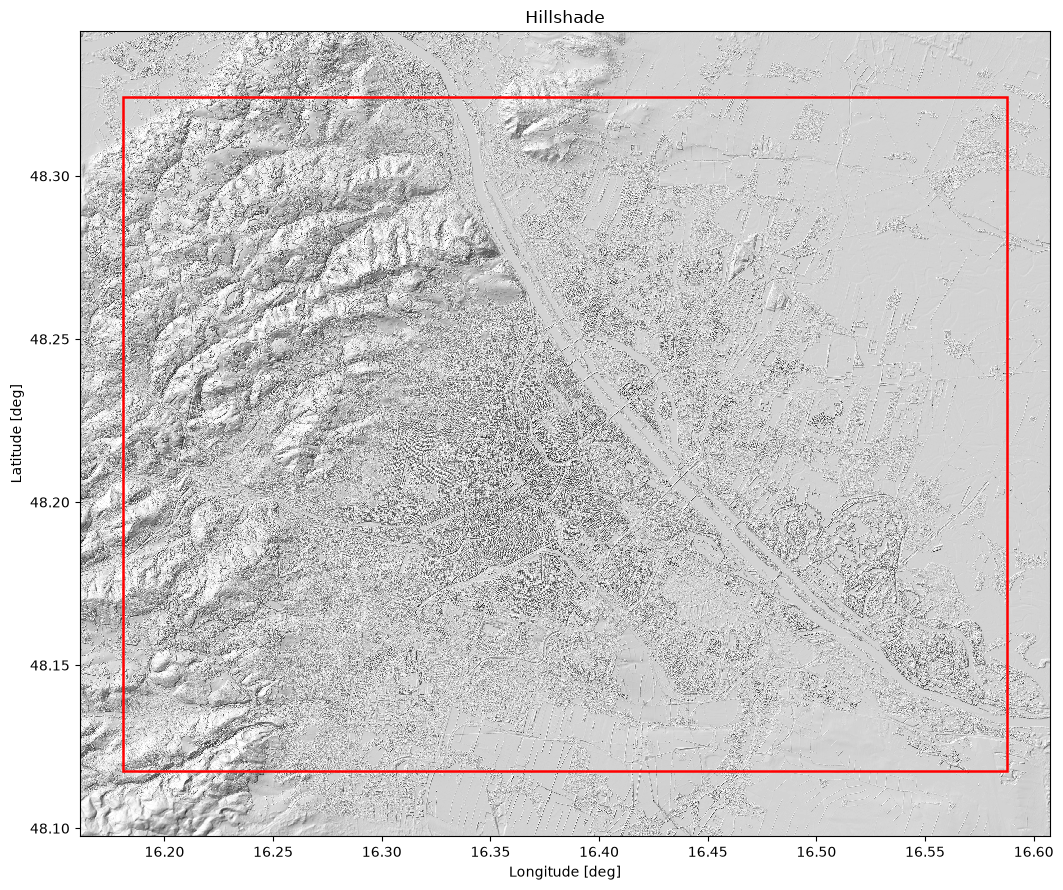

In [6]:
fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(hs, cmap="gray", extent=extent, aspect=aspect, interpolation="none")
add_outlines(ax)
ax.set_title("Hillshade")
plt.tight_layout(); plt.show()

## Height distribution inside the AOI

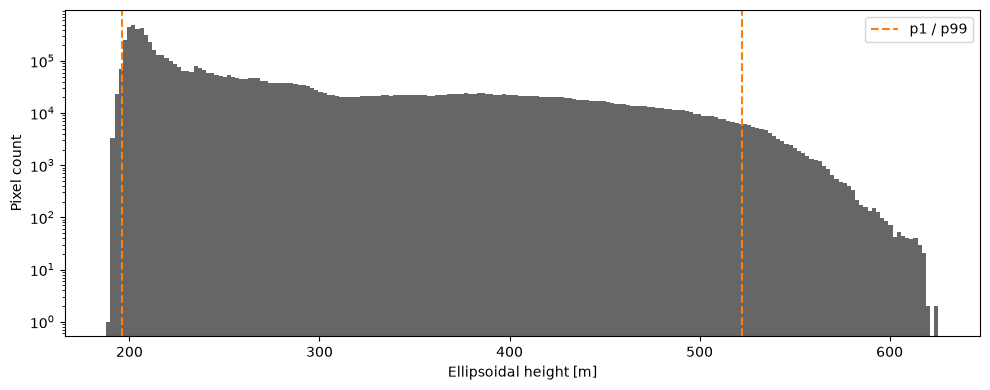

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(aoi_vals, bins=200, color="0.4")
ax.axvline(vmin, color="C1", ls="--", label=f"p{CLIP_PERCENTILES[0]} / p{CLIP_PERCENTILES[1]}")
ax.axvline(vmax, color="C1", ls="--")
ax.set_xlabel("Ellipsoidal height [m]"); ax.set_ylabel("Pixel count"); ax.set_yscale("log")
ax.legend(); plt.tight_layout(); plt.show()

## Context: whole DEM (decimated) with the AOI

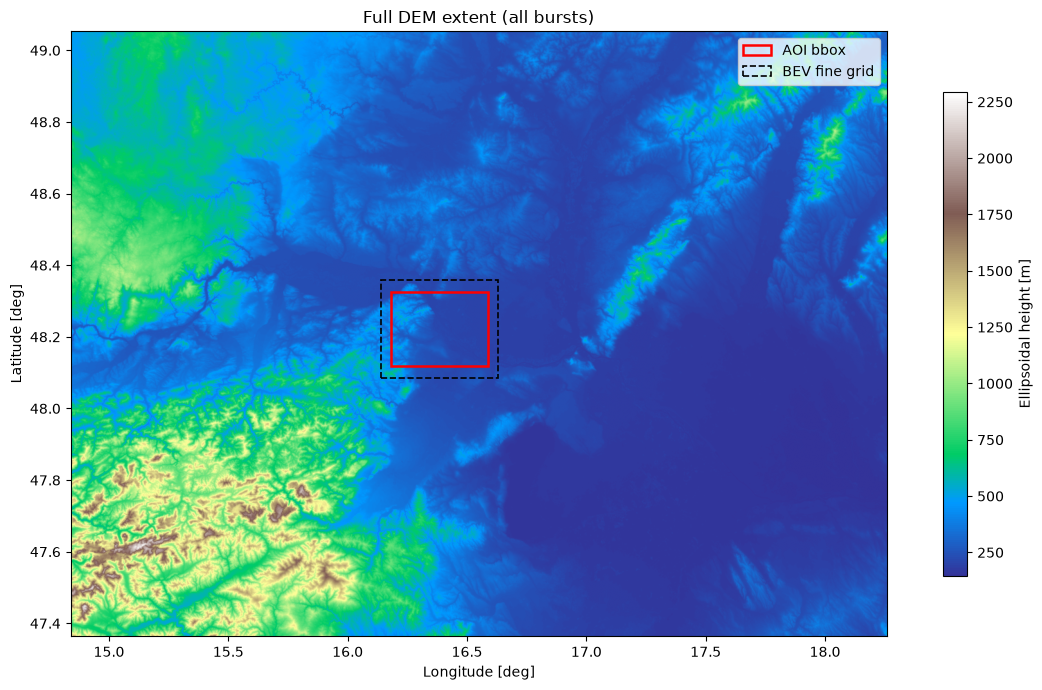

In [8]:
DECIM = 20
with rasterio.open(DEM_FILE) as src:
    ov = src.read(1, out_shape=(src.height // DECIM, src.width // DECIM), masked=True,
                  resampling=rasterio.enums.Resampling.average)
    b = src.bounds

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(ov, cmap="terrain", extent=(b.left, b.right, b.bottom, b.top),
               aspect=1 / np.cos(np.deg2rad(0.5 * (b.bottom + b.top))))
add_outlines(ax)
ax.set_xlim(b.left, b.right); ax.set_ylim(b.bottom, b.top)
ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, shrink=0.8, label="Ellipsoidal height [m]")
ax.set_title("Full DEM extent (all bursts)")
plt.tight_layout(); plt.show()

## Pixel size: is it 10 m everywhere?

Two different things matter:

1. **Grid spacing of the final GeoTIFF**: one regular grid in **degrees** (EPSG:4326) over the whole extent. Its spacing in metres is ~10 m,
   but the east-west size shrinks with `cos(lat)`, so it changes a little from south to north.
2. **Native resolution of the data**: the final grid was made from two parts (`*_parts/`):
   * `fine_10m_ellipsoid.tif`: BEV DSM (1 m ALS, averaged to 10 m), **only inside the fine grid**
   * `coarse_ellipsoid.tif`: Copernicus GLO-30, **everywhere else**, upsampled bilinearly to the 10 m grid. It has 10 m pixels, but it only holds ~30 m of detail.

Pixel sizes in metres are computed geodesically on the WGS84 ellipsoid at the centre latitude of each file.

In [9]:
import pandas as pd
from pyproj import Geod

geod = Geod(ellps="WGS84")
PARTS_DIR = DEM_DIR / "vienna_bevdsm_cop30_ellipsoid_10m_parts"

def pixel_size_m(res_lon, res_lat, lat):
    """Geodesic east-west / north-south size [m] of one pixel at latitude lat."""
    _, _, dx = geod.inv(0, lat, res_lon, lat)
    _, _, dy = geod.inv(0, lat - res_lat / 2, 0, lat + res_lat / 2)
    return dx, dy

rows_ = []
for label, path in [
    ("final GeoTIFF (whole grid)", DEM_FILE),
    ("fine part: BEV DSM", PARTS_DIR / "fine_10m_ellipsoid.tif"),
    ("coarse part: COP30", PARTS_DIR / "coarse_ellipsoid.tif"),
]:
    with rasterio.open(path) as src:
        rx, ry = src.res
        bb = src.bounds
    lat_mid = 0.5 * (bb.bottom + bb.top)
    dx_s, _ = pixel_size_m(rx, ry, bb.bottom)
    dx_c, dy_c = pixel_size_m(rx, ry, lat_mid)
    dx_n, _ = pixel_size_m(rx, ry, bb.top)
    rows_.append({
        "dataset": label,
        "size [px]": f"{src.width} x {src.height}",
        "res lon [arcsec]": rx * 3600,
        "res lat [arcsec]": ry * 3600,
        "dx E-W centre [m]": dx_c,
        "dy N-S [m]": dy_c,
        "dx south edge [m]": dx_s,
        "dx north edge [m]": dx_n,
    })

res_table = pd.DataFrame(rows_).set_index("dataset")
res_table.style.format(precision=2)

,size [px],res lon [arcsec],res lat [arcsec],dx E-W centre [m],dy N-S [m],dx south edge [m],dx north edge [m]
dataset,,,,,,,
final GeoTIFF (whole grid),25410 x 18788,0.48,0.32,10.00,10.00,10.17,9.84
fine part: BEV DSM,3625 x 3038,0.48,0.32,10.00,10.00,10.03,9.97
coarse part: COP30,12316 x 6088,1.00,1.00,20.65,30.89,20.98,20.30


In [10]:
# pixel size of the final grid inside the AOI
dx_aoi_s, dy_aoi = pixel_size_m(win_transform.a, -win_transform.e, s)
dx_aoi_n, _ = pixel_size_m(win_transform.a, -win_transform.e, n)
fw, fs, fe, fn = fine_bounds
aoi_inside_fine = (w >= fw) and (e <= fe) and (s >= fs) and (n <= fn)

print(f"Final grid inside the AOI: dx = {dx_aoi_n:.2f} .. {dx_aoi_s:.2f} m (north .. south), dy = {dy_aoi:.2f} m")
print(f"AOI completely inside the BEV fine grid: {aoi_inside_fine}  "
      f"-> {'native 10 m data in the whole AOI' if aoi_inside_fine else 'part of the AOI is upsampled COP30'}")
print(f"(COP30 blends into BEV over {report['merge']['blend_width_m']:.0f} m inside the fine grid border)")

Final grid inside the AOI: dx = 9.98 .. 10.02 m (north .. south), dy = 10.00 m
AOI completely inside the BEV fine grid: True  -> native 10 m data in the whole AOI
(COP30 blends into BEV over 300 m inside the fine grid border)


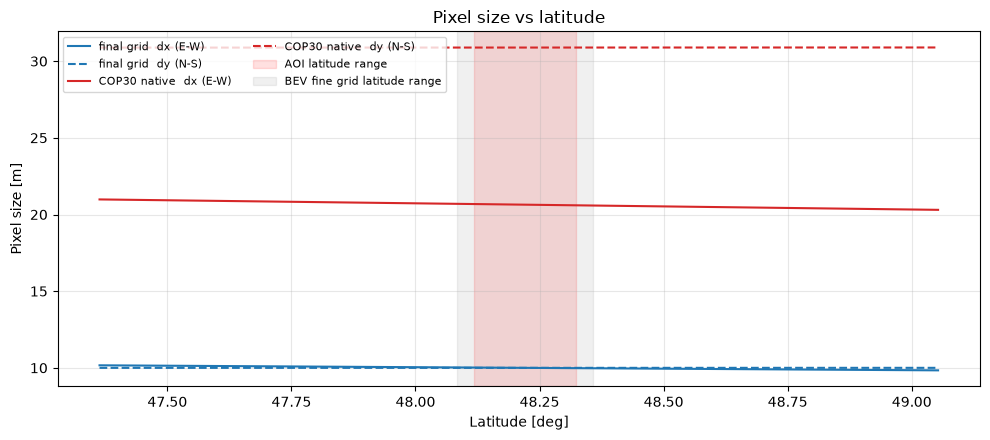

In [11]:
# grid spacing [m] vs latitude across the whole DEM extent
with rasterio.open(DEM_FILE) as src:
    rx, ry = src.res
    b = src.bounds
lats = np.linspace(b.bottom, b.top, 100)
dx_lat = np.array([pixel_size_m(rx, ry, la)[0] for la in lats])
dy_lat = np.array([pixel_size_m(rx, ry, la)[1] for la in lats])

with rasterio.open(PARTS_DIR / "coarse_ellipsoid.tif") as src:
    crx, cry = src.res
dxc_lat = np.array([pixel_size_m(crx, cry, la)[0] for la in lats])
dyc_lat = np.array([pixel_size_m(crx, cry, la)[1] for la in lats])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(lats, dx_lat, "C0", label="final grid  dx (E-W)")
ax.plot(lats, dy_lat, "C0--", label="final grid  dy (N-S)")
ax.plot(lats, dxc_lat, "C3", label="COP30 native  dx (E-W)")
ax.plot(lats, dyc_lat, "C3--", label="COP30 native  dy (N-S)")
ax.axvspan(s, n, color="red", alpha=0.12, label="AOI latitude range")
ax.axvspan(fs, fn, color="k", alpha=0.06, label="BEV fine grid latitude range")
ax.set_xlabel("Latitude [deg]"); ax.set_ylabel("Pixel size [m]")
ax.set_title("Pixel size vs latitude")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Map: native resolution of the data

Over the full extent, coloured by the data that fills each pixel. Every pixel is on the 10 m grid,
but only the dark-blue block holds real 10 m (BEV) data.

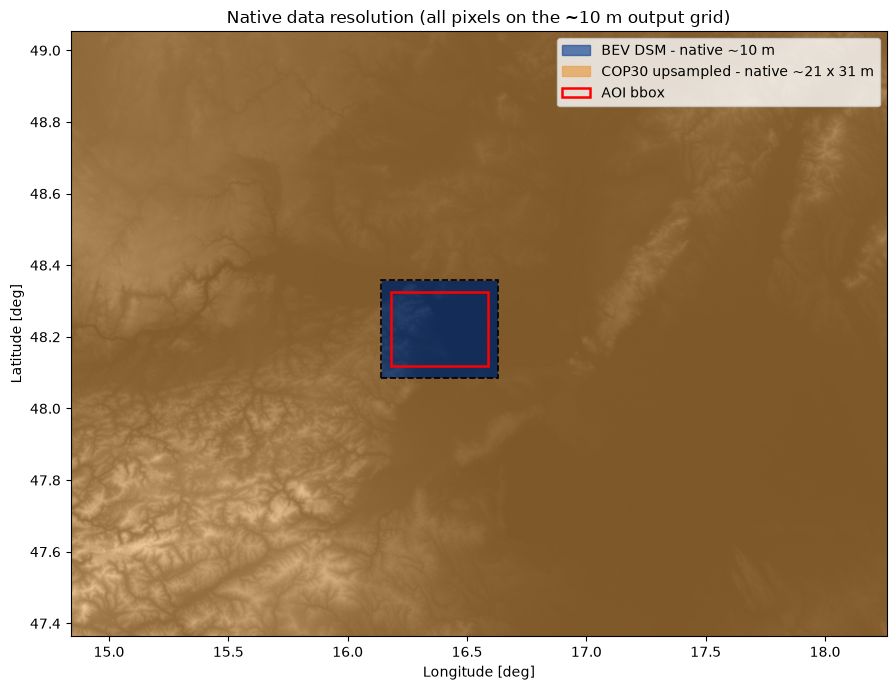

In [12]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

with rasterio.open(DEM_FILE) as src:
    b = src.bounds
    h, wd = src.height // DECIM, src.width // DECIM
    tr = src.transform * src.transform.scale(src.width / wd, src.height / h)

rr, cc = np.indices((h, wd))
lon_o = tr.c + (cc + 0.5) * tr.a
lat_o = tr.f + (rr + 0.5) * tr.e
src_map = np.where((lon_o >= fw) & (lon_o <= fe) & (lat_o >= fs) & (lat_o <= fn), 1, 0)
src_map = np.ma.masked_where(np.ma.getmaskarray(ov), src_map)

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(ov, cmap="gray", extent=(b.left, b.right, b.bottom, b.top),
          aspect=1 / np.cos(np.deg2rad(0.5 * (b.bottom + b.top))))
ax.imshow(src_map, cmap=ListedColormap(["#e6a04a", "#1f4e9c"]), vmin=0, vmax=1, alpha=0.55,
          extent=(b.left, b.right, b.bottom, b.top),
          aspect=1 / np.cos(np.deg2rad(0.5 * (b.bottom + b.top))))
add_outlines(ax)
ax.set_xlim(b.left, b.right); ax.set_ylim(b.bottom, b.top)
ax.legend(handles=[
    Patch(color="#1f4e9c", alpha=0.7, label=f"BEV DSM - native ~{res_table.iloc[1]['dx E-W centre [m]']:.0f} m"),
    Patch(color="#e6a04a", alpha=0.7, label=f"COP30 upsampled - native ~{res_table.iloc[2]['dx E-W centre [m]']:.0f} x {res_table.iloc[2]['dy N-S [m]']:.0f} m"),
    Rectangle((0, 0), 1, 1, fill=False, ec="red", lw=1.8, label="AOI bbox"),
], loc="upper right")
ax.set_title("Native data resolution (all pixels on the ~10 m output grid)")
plt.tight_layout(); plt.show()